In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import random
from scipy.stats import kurtosis

In [2]:
SEED = 42
DEFAULT_REGIME_PARAMS = {
    0: {'drift': 0.18,  'vol_mult': 0.7,  'name': 'Bull'},
    1: {'drift': -0.10, 'vol_mult': 1.1,  'name': 'Bear'},
    2: {'drift': -0.25, 'vol_mult': 2.0,  'name': 'Crisis'},
    3: {'drift': 0.02,  'vol_mult': 1.5,  'name': 'Choppy'},
}

DEFAULT_TRANSITION_MATRIX = np.array([
    [0.95, 0.03, 0.01, 0.01],  # from Bull
    [0.05, 0.90, 0.03, 0.02],  # from Bear
    [0.15, 0.25, 0.55, 0.05],  # from Crisis
    [0.20, 0.15, 0.05, 0.60],  # from Choppy
])

In [3]:
def simulate_gbm(mu,sigma,S0,T,seed) -> np.ndarray:
    """
    Simulate a single price path using Geometric Brownian Motion.

    Parameters
    ----------
    mu    : Annual drift (e.g. 0.10 for 10%)
    sigma : Annual volatility (e.g. 0.187 for 18.7%)
    S0    : Starting price
    T     : Number of trading days
    seed  : RNG seed

    Returns
    -------
    np.ndarray of length T (prices).
    """

    rng = np.random.default_rng(seed)
    dt = 1 / 252

    daily_mu = mu * dt
    daily_sigma = sigma * np.sqrt(dt)

    log_returns = daily_mu - 0.5 * sigma ** 2 * dt + daily_sigma * rng.standard_normal(T)
    prices = S0 * np.exp(np.cumsum(np.insert(log_returns, 0, 0)))

    return prices[1:]

def simulate_garch(mu,omega,alpha,beta,S0,T,seed) -> tuple[np.ndarray, np.ndarray]:
    """
    Simulate price path with GARCH(1,1) volatility dynamics.

    Parameters
    ----------
    mu    : Annual drift
    omega : Long-run variance floor (e.g. 2e-6)
    alpha : ARCH term — sensitivity to recent shocks (e.g. 0.09)
    beta  : GARCH term — variance persistence (e.g. 0.89)
    S0    : Starting price
    T     : Number of trading days
    seed  : RNG seed

    Returns
    -------
    (prices, annualised_conditional_volatilities), each length T.
    """
    rng = np.random.default_rng(seed)
    dt = 1 / 252

    long_run_var = omega / (1 - alpha - beta)
    variances = np.zeros(T)
    returns = np.zeros(T)
    variances[0] = long_run_var

    for t in range(T):
        z = rng.standard_normal()
        returns[t] = mu * dt + np.sqrt(variances[t] * dt) * z

        epsilon_sq = (returns[t] - mu * dt) ** 2
        if t + 1 < T:
            variances[t + 1] = omega + alpha * epsilon_sq / dt + beta * variances[t]

    prices = S0 * np.exp(np.cumsum(np.insert(returns, 0, 0)))
    vols = np.sqrt(variances * 252)

    return prices[1:], vols


def draw_fat_tail_shocks(T, nu, seed) -> np.ndarray:
    """
    Draw T noise samples from a unit-variance Student's t distribution.

    Parameters
    ----------
    T    : Number of samples
    nu   : Degrees of freedom.
           nu=4.51 → excess kurtosis ~11.7 (matches SPY)
           nu=6.0  → moderate fat tails
           nu=30   → close to Gaussian
    seed : RNG seed

    Returns
    -------
    np.ndarray of unit-variance t-distributed shocks, length T.
    """
    rng = np.random.default_rng(seed)
    raw = rng.standard_t(nu, size=T)
    scale = np.sqrt((nu - 2) / nu)  # normalise to unit variance
    return raw * scale


def simulate_ou_process(theta,mu,sigma,X0,T,seed) -> np.ndarray:
    """
    Simulate an Ornstein-Uhlenbeck mean-reverting process.

    Parameters
    ----------
    theta : Mean-reversion speed (higher → faster reversion)
    mu    : Long-run mean
    sigma : Diffusion coefficient
    X0    : Starting value
    T     : Number of steps
    seed  : RNG seed

    Returns
    -------
    np.ndarray of length T+1 (includes X0).
    """
    rng = np.random.default_rng(seed)
    dt = 1 / 252

    path = np.zeros(T + 1)
    path[0] = X0

    for t in range(T):
        drift = theta * (mu - path[t]) * dt
        diffusion = sigma * np.sqrt(dt) * rng.standard_normal()
        path[t + 1] = path[t] + drift + diffusion

    return path


def simulate_regime_sequence(T,initial_regime=0,transition_matrix= None,seed=42) -> np.ndarray:
    """
    Simulate a regime label sequence using a Markov chain.

    Parameters
    ----------
    T                 : Number of days
    initial_regime    : Starting regime index (0=Bull, 1=Bear, 2=Crisis, 3=Choppy)
    transition_matrix : (4×4) row-stochastic matrix. Uses DEFAULT_TRANSITION_MATRIX if None.
    seed              : RNG seed

    Returns
    -------
    np.ndarray of int regime indices, length T.
    """
    if transition_matrix is None:
        transition_matrix = DEFAULT_TRANSITION_MATRIX

    rng = np.random.default_rng(seed)
    regimes = np.zeros(T, dtype=int)
    regimes[0] = initial_regime

    for t in range(1, T):
        regimes[t] = rng.choice(len(transition_matrix), p=transition_matrix[regimes[t - 1]])

    return regimes


In [4]:
# class SyntheticMarketGenerator:
#     """
#     Full stochastic market generator.

#     Combines GBM + GARCH(1,1) + Student-t fat tails +
#     Ornstein-Uhlenbeck mean reversion + Markov regime switching.

#     SPY-calibrated defaults:
#         mu=0.10, sigma=0.187, garch_alpha=0.09, garch_beta=0.89, t_nu=4.51

#     Usage
#     -----
#     gen = SyntheticMarketGenerator()
#     df  = gen.generate(T=252, S0=450.0, seed=42)
#     """

#     def __init__(
#         self,
#         # GBM baseline
#         mu: float = 0.20,
#         sigma: float = 0.187,
#         # GARCH
#         garch_omega: float = 2e-6,
#         garch_alpha: float = 0.09,
#         garch_beta: float = 0.89,
#         # Fat tails (Student's t degrees of freedom)
#         t_nu: float = 4.51,
#         # Mean reversion speed
#         mr_theta: float = 0.08,
#         # Regime switching
#         use_regimes: bool = True,
#         transition_matrix: np.ndarray = None,
#         regime_params: dict = None,
#     ):
#         self.mu = mu
#         self.sigma = sigma
#         self.garch_omega = garch_omega
#         self.garch_alpha = garch_alpha
#         self.garch_beta = garch_beta
#         self.t_nu = t_nu
#         self.mr_theta = mr_theta
#         self.use_regimes = use_regimes
#         self.transition_matrix = transition_matrix if transition_matrix is not None \
#             else DEFAULT_TRANSITION_MATRIX
#         self.regime_params = regime_params if regime_params is not None \
#             else DEFAULT_REGIME_PARAMS

#     def generate(
#         self,
#         T: int = 252,
#         S0: float = 100.0,
#         initial_regime: int = 0,
#         seed: int = 42,
#     ) -> pd.DataFrame:
#         """
#         Generate T days of synthetic price data.

#         Returns
#         -------
#         pd.DataFrame with columns:
#             price, daily_return, log_return, regime, regime_name,
#             conditional_vol (annualised), garch_var
#         """
#         rng = np.random.default_rng(seed)
#         dt = 1 / 252

#         # Step 1: regime sequence
#         regimes = np.zeros(T, dtype=int)
#         regimes[0] = initial_regime
#         if self.use_regimes:
#             for t in range(1, T):
#                 regimes[t] = rng.choice(4, p=self.transition_matrix[regimes[t - 1]])

#         # Step 2: GARCH initialisation
#         long_run_var = self.garch_omega / (1 - self.garch_alpha - self.garch_beta)
#         garch_var = np.zeros(T)
#         garch_var[0] = long_run_var

#         # Step 3: fat-tail shocks
#         raw_shocks = rng.standard_t(self.t_nu, size=T)
#         shocks = raw_shocks * np.sqrt((self.t_nu - 2) / self.t_nu)

#         # Step 4: build returns
#         log_returns = np.zeros(T)
#         prev_log_return = 0.0

#         for t in range(T):
#             regime = regimes[t]
#             regime_drift = self.regime_params[regime]['drift'] if self.use_regimes else self.mu
#             regime_vol_mult = self.regime_params[regime]['vol_mult'] if self.use_regimes else 1.0

#             daily_vol = np.sqrt(garch_var[t]) * regime_vol_mult
#             daily_vol = max(daily_vol, 0.001)

#             mr_adj = -self.mr_theta * prev_log_return * dt
#             drift_term = regime_drift * dt - 0.5 * (daily_vol ** 2)

#             log_returns[t] = drift_term + daily_vol * shocks[t] + mr_adj
#             prev_log_return = log_returns[t]

#             if t + 1 < T:
#                 epsilon_sq = ((log_returns[t] - regime_drift * dt) ** 2)/(regime_vol_mult ** 2)
#                 garch_var[t + 1] = (
#                     self.garch_omega
#                     + self.garch_alpha * epsilon_sq 
#                     + self.garch_beta * garch_var[t]
#                 )
#                 garch_var[t + 1] = max(garch_var[t + 1], 1e-8)

#         # Step 5: prices
#         prices = S0 * np.exp(np.cumsum(log_returns))
#         daily_returns = np.exp(log_returns) - 1

#         df = pd.DataFrame({
#             'price':           prices,
#             'daily_return':    daily_returns,
#             'log_return':      log_returns,
#             'regime':          regimes,
#             'regime_name':     [self.regime_params[r]['name'] for r in regimes],
#             'conditional_vol': np.sqrt(garch_var * 252),
#             'garch_var':       garch_var,
#         })
#         df.index.name = 'day'

#         return df

# gen = SyntheticMarketGenerator()

In [5]:
import numpy as np
import pandas as pd

# Paste this over your existing SyntheticMarketGenerator cell.
# It expects DEFAULT_REGIME_PARAMS and DEFAULT_TRANSITION_MATRIX to already be defined.
# Changes for semi-Markov regime durations are marked  # NEW


# =============================================================================
# NEW: semi-Markov regime durations
# =============================================================================

# How long each regime lasts once it starts (in trading days).
# Supported specs:
#   {'dist': 'lognormal', 'median': m, 'sigma': s}   mean = m * exp(s**2 / 2)
#   {'dist': 'pareto',    'xmin': x, 'alpha': a}      mean = a * x / (a - 1); keep a > 1.5
#   {'dist': 'uniform',   'low': lo, 'high': hi}      whole days, inclusive
#   {'dist': 'geometric', 'p_stay': p}                identical to the old Markov chain
DEFAULT_REGIME_DURATIONS = {
    0: {'dist': 'lognormal', 'median': 80, 'sigma': 0.9},  # Bull:   mean ~120 days, long right tail
    1: {'dist': 'lognormal', 'median': 50, 'sigma': 0.8},  # Bear:   mean ~69 days
    2: {'dist': 'uniform',   'low': 5,     'high': 30},    # Crisis: 5-30 days
    3: {'dist': 'lognormal', 'median': 45, 'sigma': 0.6},  # Choppy: mean ~54 days
}
# Pareto alternative for heavier trend tails, e.g.
#   0: {'dist': 'pareto', 'xmin': 30, 'alpha': 1.8}   # mean ~68 days, ~2% of regimes last > 1 year


def draw_regime_duration(rng, spec, max_duration=756):
    """Draw one regime duration in whole days (at least 1, at most max_duration)."""
    dist = spec['dist']
    if dist == 'lognormal':
        d = rng.lognormal(mean=np.log(spec['median']), sigma=spec['sigma'])
    elif dist == 'pareto':
        d = spec['xmin'] * (1.0 + rng.pareto(spec['alpha']))  # numpy's pareto is Lomax; +1 gives classic Pareto
    elif dist == 'uniform':
        d = rng.integers(spec['low'], spec['high'] + 1)
    elif dist == 'geometric':
        d = rng.geometric(1.0 - spec['p_stay'])
    else:
        raise ValueError(f"Unknown duration distribution: {dist}")
    return int(min(max(round(d), 1), max_duration))


def jump_matrix_from_transition(transition_matrix):
    """
    Turn a Markov transition matrix into a jump matrix: zero the diagonal
    (staying is now handled by the duration) and rescale each row to sum to 1.
    """
    J = np.array(transition_matrix, dtype=float).copy()
    np.fill_diagonal(J, 0.0)
    row_sums = J.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0):
        raise ValueError("Every regime needs a non-zero probability of moving to another regime")
    return J / row_sums


def simulate_semi_markov_regimes(T, initial_regime, transition_matrix, regime_durations,
                                 rng, max_duration=756):
    """
    Regime sequence where each regime lasts for a duration drawn from its own
    distribution, then jumps to a different regime via the jump matrix.
    """
    J = jump_matrix_from_transition(transition_matrix)
    n = len(J)
    regimes = np.empty(T, dtype=int)

    t, r = 0, initial_regime
    while t < T:
        d = draw_regime_duration(rng, regime_durations[r], max_duration)
        regimes[t:t + d] = r          # slicing past T is safe; the last regime is cut off
        t += d
        r = rng.choice(n, p=J[r])
    return regimes


def regime_duration_summary(regime_paths, regime_params):
    """
    Realised regime durations, pooled over one or more paths.
    Pass a single regime array or a list of them (e.g. from many seeds).
    The final regime of each path is excluded because it is cut off at T.
    """
    if isinstance(regime_paths, np.ndarray) and regime_paths.ndim == 1:
        regime_paths = [regime_paths]

    lengths_all, labels_all, counts = [], [], np.zeros(len(regime_params))
    total_days = 0
    for regimes in regime_paths:
        regimes = np.asarray(regimes)
        change = np.flatnonzero(np.diff(regimes)) + 1
        starts = np.r_[0, change]
        lengths = np.diff(np.r_[starts, len(regimes)])
        labels = regimes[starts]
        lengths_all.append(lengths[:-1])
        labels_all.append(labels[:-1])
        counts += np.bincount(regimes, minlength=len(regime_params))
        total_days += len(regimes)

    lengths_all = np.concatenate(lengths_all)
    labels_all = np.concatenate(labels_all)

    rows = []
    for r, p in regime_params.items():
        L = lengths_all[labels_all == r]
        has = len(L) > 0
        rows.append({
            'regime':      p['name'],
            'episodes':    len(L),
            'mean_days':   L.mean() if has else np.nan,
            'median_days': np.median(L) if has else np.nan,
            'p95_days':    np.percentile(L, 95) if has else np.nan,
            'max_days':    L.max() if has else np.nan,
            'time_share':  counts[r] / total_days,
        })
    return pd.DataFrame(rows).set_index('regime')


# =============================================================================
# Market generator
# =============================================================================

class SyntheticMarketGenerator:
    """
    Full stochastic market generator with OHLC bars.

    Combines GBM + GARCH(1,1) + Student-t fat tails +
    mean reversion + regime switching (semi-Markov by default).

    Each day's return is split into an overnight gap (close -> open) and an
    intraday move (open -> close). The intraday path is a Brownian bridge
    pinned to the open and close, and its max/min give the high/low.

    Usage
    -----
    gen = SyntheticMarketGenerator()
    df  = gen.generate(T=252, S0=450.0, seed=42)
    df  = add_atr(df, period=14)
    """

    def __init__(
        self,
        # GBM baseline
        mu: float = 0.12,
        sigma: float = 0.15,
        # GARCH (daily variance units)
        garch_omega: float = 2e-6,
        garch_alpha: float = 0.09,
        garch_beta: float = 0.89,
        # Fat tails (Student's t degrees of freedom)
        t_nu: float = 4.51,
        # Mean reversion speed
        mr_theta: float = 0.08,
        # Regime switching
        use_regimes: bool = True,
        transition_matrix: np.ndarray = None,
        regime_params: dict = None,
        # NEW: regime durations
        duration_model: str = 'semi_markov',   # 'semi_markov' or 'markov' (the old day-by-day chain)
        regime_durations: dict = None,
        max_regime_duration: int = 252*4,        # cap any single regime at ~4 years
        # OHLC construction
        overnight_var_share: float = 0.25,     # share of daily variance in the overnight gap
        n_substeps: int = 78,                  # intraday steps per bar (78 = 5-min bars in a 6.5h session)
    ):
        self.mu = mu
        self.sigma = sigma
        self.garch_omega = garch_omega
        self.garch_alpha = garch_alpha
        self.garch_beta = garch_beta
        self.t_nu = t_nu
        self.mr_theta = mr_theta
        self.use_regimes = use_regimes
        self.transition_matrix = transition_matrix if transition_matrix is not None \
            else DEFAULT_TRANSITION_MATRIX
        self.regime_params = regime_params if regime_params is not None \
            else DEFAULT_REGIME_PARAMS

        # NEW
        if duration_model not in ('semi_markov', 'markov'):
            raise ValueError("duration_model must be 'semi_markov' or 'markov'")
        self.duration_model = duration_model
        self.regime_durations = regime_durations if regime_durations is not None \
            else DEFAULT_REGIME_DURATIONS
        self.max_regime_duration = int(max_regime_duration)

        if not 0.0 <= overnight_var_share < 1.0:
            raise ValueError("overnight_var_share must be in [0, 1)")
        self.overnight_var_share = overnight_var_share
        self.n_substeps = int(n_substeps)

    def generate(
        self,
        T: int = 252,
        S0: float = 100.0,
        initial_regime: int = 0,
        seed: int = 42,
    ) -> pd.DataFrame:
        """
        Generate T days of synthetic OHLC data.

        Returns
        -------
        pd.DataFrame with columns:
            open, high, low, close, price (= close), daily_return, log_return,
            overnight_return, intraday_return, regime, regime_name,
            conditional_vol (GARCH only, annualised),
            effective_vol (GARCH x regime multiplier, annualised), garch_var
        """
        rng = np.random.default_rng(seed)
        dt = 1 / 252
        w = self.overnight_var_share

        # Step 1: regime sequence  # NEW: semi-Markov option
        if not self.use_regimes:
            regimes = np.zeros(T, dtype=int)
            regimes[0] = initial_regime
        elif self.duration_model == 'semi_markov':
            regimes = simulate_semi_markov_regimes(
                T, initial_regime, self.transition_matrix, self.regime_durations,
                rng, self.max_regime_duration,
            )
        else:  # original day-by-day Markov chain
            regimes = np.zeros(T, dtype=int)
            regimes[0] = initial_regime
            for t in range(1, T):
                regimes[t] = rng.choice(4, p=self.transition_matrix[regimes[t - 1]])

        # Step 2: GARCH initialisation (daily variance)
        long_run_var = self.garch_omega / (1 - self.garch_alpha - self.garch_beta)
        garch_var = np.zeros(T)
        garch_var[0] = long_run_var

        # Step 3: fat-tail shocks, separate for the overnight gap and the intraday move
        t_scale = np.sqrt((self.t_nu - 2) / self.t_nu)  # normalise to unit variance
        overnight_shocks = rng.standard_t(self.t_nu, size=T) * t_scale
        intraday_shocks = rng.standard_t(self.t_nu, size=T) * t_scale

        # Step 4: build returns
        log_returns = np.zeros(T)
        overnight_returns = np.zeros(T)
        intraday_returns = np.zeros(T)
        daily_vols = np.zeros(T)
        prev_log_return = 0.0

        for t in range(T):
            regime = regimes[t]
            regime_drift = self.regime_params[regime]['drift'] if self.use_regimes else self.mu
            regime_vol_mult = self.regime_params[regime]['vol_mult'] if self.use_regimes else 1.0

            daily_vol = np.sqrt(garch_var[t]) * regime_vol_mult
            daily_vol = max(daily_vol, 0.001)
            daily_vols[t] = daily_vol

            mr_adj = -self.mr_theta * prev_log_return * dt
            drift_term = regime_drift * dt - 0.5 * (daily_vol ** 2)

            # Split the day's shock into overnight gap + intraday move.
            # Variances add to daily_vol**2, so the close-to-close series keeps the same volatility.
            overnight_returns[t] = np.sqrt(w) * daily_vol * overnight_shocks[t]
            intraday_returns[t] = drift_term + np.sqrt(1 - w) * daily_vol * intraday_shocks[t] + mr_adj
            log_returns[t] = overnight_returns[t] + intraday_returns[t]
            prev_log_return = log_returns[t]

            if t + 1 < T:
                epsilon_sq = ((log_returns[t] - regime_drift * dt) ** 2) / (regime_vol_mult ** 2)
                garch_var[t + 1] = (
                    self.garch_omega
                    + self.garch_alpha * epsilon_sq
                    + self.garch_beta * garch_var[t]
                )
                garch_var[t + 1] = max(garch_var[t + 1], 1e-8)

        if not np.all(np.isfinite(log_returns)):
            raise FloatingPointError(f"Non-finite returns generated (seed={seed})")

        # Step 5: close and open prices
        close = S0 * np.exp(np.cumsum(log_returns))
        prev_close = np.r_[S0, close[:-1]]
        open_ = prev_close * np.exp(overnight_returns)

        # Step 6: high and low from an intraday Brownian bridge
        intraday_vols = np.sqrt(1 - w) * daily_vols
        high, low = self._intraday_high_low(open_, intraday_returns, intraday_vols, rng)

        daily_returns = np.exp(log_returns) - 1

        df = pd.DataFrame({
            'open':             open_,
            'high':             high,
            'low':              low,
            'close':            close,
            'price':            close,  # kept so existing code still works
            'daily_return':     daily_returns,
            'log_return':       log_returns,
            'overnight_return': overnight_returns,
            'intraday_return':  intraday_returns,
            'regime':           regimes,
            'regime_name':      [self.regime_params[r]['name'] for r in regimes],
            'conditional_vol':  np.sqrt(garch_var * 252),
            'effective_vol':    daily_vols * np.sqrt(252),
            'garch_var':        garch_var,
        })
        df.index.name = 'day'

        return df

    def _intraday_high_low(self, open_, intraday_returns, intraday_vols, rng):
        """
        Build each day's intraday log-price path as a Brownian bridge that starts
        at the open and ends exactly at the close, then take its max and min.
        """
        T = len(open_)
        N = self.n_substeps

        # Random walk of N steps, scaled so its total variance equals the day's intraday variance
        steps = rng.standard_normal((T, N)) * (intraday_vols / np.sqrt(N))[:, None]
        walk = np.zeros((T, N + 1))
        walk[:, 1:] = np.cumsum(steps, axis=1)

        # Pin the walk: remove its own endpoint linearly, add the required open->close move
        frac = np.arange(N + 1) / N
        bridge = walk - frac[None, :] * walk[:, [-1]] + frac[None, :] * intraday_returns[:, None]

        # bridge[:, 0] = 0 (open) and bridge[:, -1] = intraday return (close), so both are included
        high = open_ * np.exp(bridge.max(axis=1))
        low = open_ * np.exp(bridge.min(axis=1))
        return high, low


def add_atr(df: pd.DataFrame, period: int = 14) -> pd.DataFrame:
    """Add true range and Wilder-smoothed ATR columns."""
    prev_close = df['close'].shift(1)
    true_range = pd.concat([
        df['high'] - df['low'],
        (df['high'] - prev_close).abs(),
        (df['low'] - prev_close).abs(),
    ], axis=1).max(axis=1)

    df['true_range'] = true_range
    df[f'atr_{period}'] = true_range.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    return df

gen = SyntheticMarketGenerator()

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

REGIME_COLOURS = {0: 'tab:green', 1: 'tab:orange', 2: 'tab:red', 3: 'tab:grey'}

def shade_regimes(ax, regimes, regime_params, colours=REGIME_COLOURS, alpha=0.25):
    """Shade contiguous blocks of each regime behind whatever is plotted on ax."""
    regimes = np.asarray(regimes)
    change = np.flatnonzero(np.diff(regimes)) + 1      # first day of each new block
    starts = np.r_[0, change]
    widths = np.r_[change, len(regimes)] - starts
    labels = regimes[starts]

    ymin, ymax = ax.get_ylim()
    for r in regime_params:
        m = labels == r
        if m.any():
            ax.broken_barh(list(zip(starts[m], widths[m])), (ymin, ymax - ymin),
                           facecolors=colours[r], alpha=alpha, linewidth=0, zorder=0)
    ax.set_ylim(ymin, ymax)

def plot_with_regimes(df, regime_params, log_price=False):
    # Effective vol = GARCH vol x regime multiplier (the conditional_vol column excludes the multiplier)
    vol_mult = df['regime'].map({r: p['vol_mult'] for r, p in regime_params.items()})
    effective_vol = df['conditional_vol'] * vol_mult * 100

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                   gridspec_kw={'height_ratios': [3, 1]})
    ax1.plot(df.index, df['price'], color='black', lw=0.8)
    if log_price:
        ax1.set_yscale('log')
    ax1.set_ylabel('Price')

    ax2.plot(df.index, effective_vol, color='black', lw=0.6)
    ax2.set_ylabel('Effective vol (%)')
    ax2.set_xlabel('Day')

    for ax in (ax1, ax2):
        shade_regimes(ax, df['regime'], regime_params)
        ax.set_xlim(df.index[0], df.index[-1])

    handles = [Patch(facecolor=REGIME_COLOURS[r], alpha=0.25, label=p['name'])
               for r, p in regime_params.items()]
    ax1.legend(handles=handles, loc='upper left')
    plt.tight_layout()
    plt.show()

% Ret 536.0739159480758
Kurtosis = 7.940812245430072


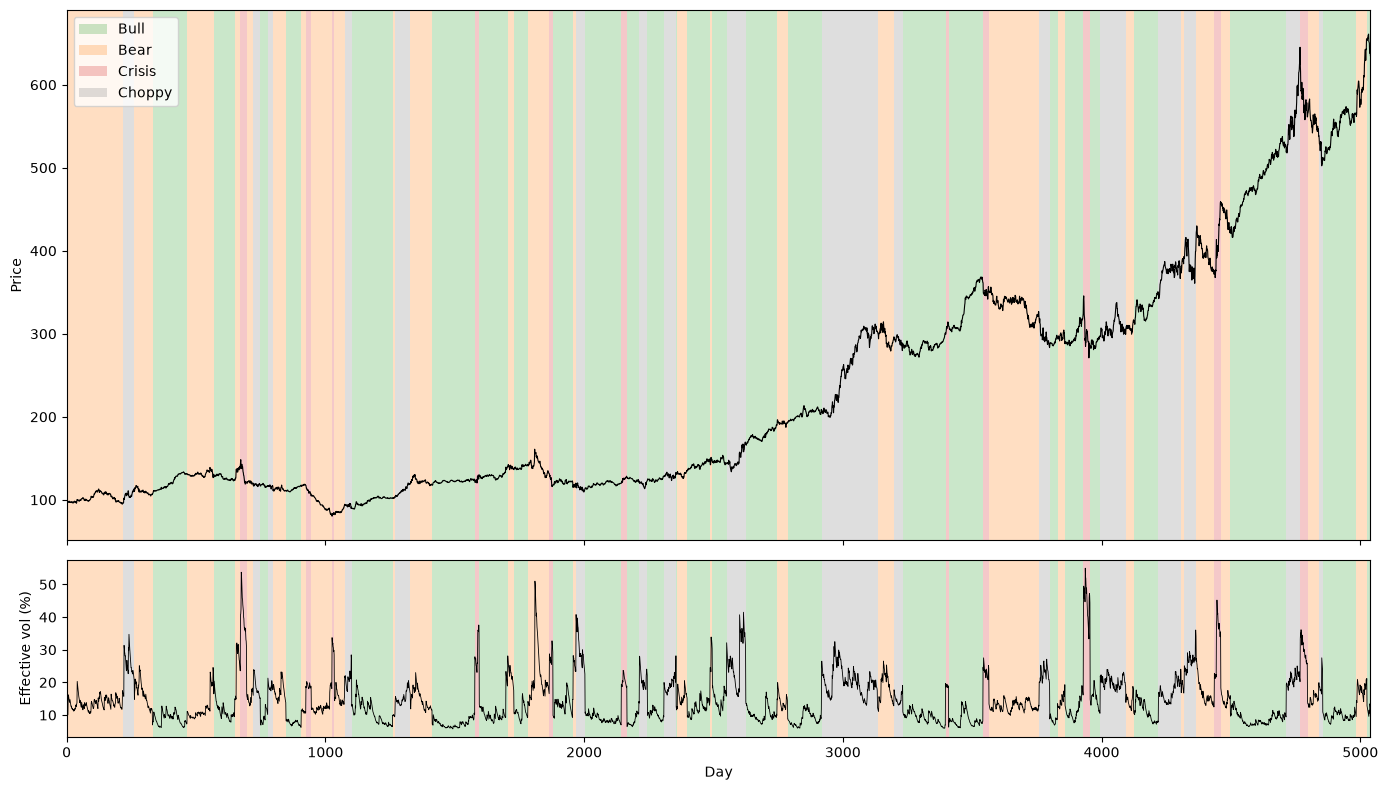

In [7]:
SEED = random.randint(0,1000000)
df  = gen.generate(T=252*20, S0=100.0, seed=SEED)
print (f"% Ret {100*(df['price'].values[-1] - df['price'].values[0])/df['price'].values[0]}")#
print(f"Kurtosis = {kurtosis(df['log_return'])}")
plot_with_regimes(df, gen.regime_params)


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Simple MA crossover with a trailing stop, plus position sizing.
# Paste below your generator cell: it uses add_atr() from synthetic_market_ohlc.py.
#
# Rules
# -----
# Entry : fast MA crosses above slow MA at the close -> buy at the next open.
#         fast MA crosses below slow MA at the close -> short at the next open (if allow_short).
#         Only a fresh crossover opens a trade; after a stop-out you wait for the next cross.
# Stops : stop_type='atr'     initial stop = entry -/+ initial_mult x ATR (ATR as of the signal close)
#                             trail = highest high (lowest low) since entry -/+ trail_mult x ATR
#         stop_type='percent' initial stop = entry x (1 -/+ initial_pct)
#                             trail = highest high (lowest low) since entry x (1 -/+ trail_pct)
#         stop_type='none'    no stop; exits only on the opposite crossover.
#                             R is then measured against a nominal risk of initial_mult x ATR.
#         Trails are updated after each close, only ever tightened, and apply from the next day.
# Fills : open gaps through the stop -> exit at the open ('gap');
#         else the day's low/high touches the stop -> exit at the stop ('stop');
#         opposite crossover -> exit at the next open ('signal'), then reverse if allowed.
#
# Sizing (decided once, at entry; the size is not changed during the trade)
# ------
#   {'method': 'notional',   'fraction': 1.0}     position value = fraction x equity
#   {'method': 'fixed_risk', 'risk_pct': 0.01}    shares = risk_pct x equity / stop distance
#   {'method': 'vol_target', 'atr_pct': 0.0033}   shares = atr_pct x equity / ATR  (1 ATR move = atr_pct of equity)
# Optional keys for every method:
#   'compound': True        size off current equity (False = off initial equity, i.e. fixed-dollar)
#   'max_leverage': 2.0     cap position value at this multiple of current equity
#   'integer_shares': False round down to whole shares (a size of 0 skips the trade)
#
# Note: fixed_risk with an ATR stop is the same as vol_target with atr_pct = risk_pct / initial_mult.
#
# The strategy only uses OHLC. Regime labels are recorded on each trade for analysis only.

DEFAULT_SIZING = {'method': 'notional', 'fraction': 1.0}


def add_ma_signals(df, fast=10, slow=20, atr_period=14):
    """Add moving averages, ATR and crossover flags (all known at each day's close)."""
    out = add_atr(df.copy(), atr_period)
    out['atr'] = out[f'atr_{atr_period}']
    out['fast_ma'] = out['close'].rolling(fast).mean()
    out['slow_ma'] = out['close'].rolling(slow).mean()

    valid = out['fast_ma'].notna() & out['slow_ma'].notna() & out['atr'].notna()
    prev_valid = valid.shift(1, fill_value=False)
    above = out['fast_ma'] > out['slow_ma']
    prev_above = above.shift(1, fill_value=False)

    out['cross_up'] = valid & prev_valid & above & ~prev_above
    out['cross_down'] = valid & prev_valid & ~above & prev_above
    return out


def position_size(sizing, equity, initial_equity, entry_px, stop_dist, atr_prev):
    """Number of shares for a new trade, and whether the leverage cap was hit."""
    method = sizing.get('method', 'notional')
    base = equity if sizing.get('compound', True) else initial_equity

    if method == 'notional':
        qty = sizing.get('fraction', 1.0) * base / entry_px
    elif method == 'fixed_risk':
        qty = sizing['risk_pct'] * base / stop_dist
    elif method == 'vol_target':
        qty = sizing['atr_pct'] * base / atr_prev
    else:
        raise ValueError(f"Unknown sizing method: {method}")

    max_qty = sizing.get('max_leverage', 2.0) * equity / entry_px
    capped = qty > max_qty
    qty = min(qty, max_qty)
    if sizing.get('integer_shares', False):
        qty = np.floor(qty)
    return qty, capped


def backtest_ma_atr(df, fast=10, slow=20, atr_period=14,
                    stop_type='atr', trail_mult=3.0, initial_mult=None,
                    trail_pct=0.05, initial_pct=None,
                    allow_short=True, exit_on_opposite_cross=True, cost_bps=0.0,
                    sizing=None, initial_equity=100_000.0):
    """
    Backtest the MA crossover / trailing stop strategy with position sizing on one OHLC path.

    Returns a dict with:
        trades : one row per trade (R-multiples, size, cash P&L, exit reason, ...)
        daily  : daily cash P&L, equity, return, position and shares
        data   : the input data with indicators and the stop level in force each day
    """
    if stop_type not in ('atr', 'percent', 'none'):
        raise ValueError("stop_type must be 'atr', 'percent' or 'none'")
    if stop_type == 'none' and not exit_on_opposite_cross:
        raise ValueError("With stop_type='none', exit_on_opposite_cross must be True or trades never close")
    initial_mult = trail_mult if initial_mult is None else initial_mult
    initial_pct = trail_pct if initial_pct is None else initial_pct
    sizing = DEFAULT_SIZING if sizing is None else sizing

    d = add_ma_signals(df, fast, slow, atr_period)
    o, h, l, c = (d[col].to_numpy() for col in ('open', 'high', 'low', 'close'))
    atr = d['atr'].to_numpy()
    up, dn = d['cross_up'].to_numpy(), d['cross_down'].to_numpy()
    regime = d['regime'].to_numpy() if 'regime' in d else None
    cost = cost_bps / 1e4
    n = len(d)

    pnl = np.zeros(n)                 # daily cash P&L
    equity_path = np.zeros(n)         # mark-to-market equity at each close
    position = np.zeros(n, dtype=int)
    shares = np.zeros(n)
    stop_line = np.full(n, np.nan)    # stop level in force during each day
    trades = []

    equity = initial_equity           # mark-to-market equity, updated through the day
    pos, pending_entry, pending_exit = 0, 0, False
    entry_px = stop = init_risk = extreme = qty = prev_mark = np.nan
    adverse = entry_atr = np.nan      # worst price against the trade, and ATR at entry
    entry_day, equity_at_entry, capped = -1, np.nan, False

    def close_trade(t, fill, reason):
        nonlocal equity, pos
        cash = pos * qty * (fill - prev_mark)
        pnl[t] += cash
        equity += cash
        worst = min(adverse, fill) if pos == 1 else max(adverse, fill)
        adverse_dist = pos * (entry_px - worst)   # how far price went against the trade (>= 0)
        trades.append({
            'direction':        'long' if pos == 1 else 'short',
            'entry_day':        entry_day,
            'exit_day':         t,
            'bars_held':        t - entry_day,
            'entry_price':      entry_px,
            'exit_price':       fill,
            'initial_risk_pct': init_risk / entry_px,
            'return_pct':       pos * (fill / entry_px - 1),
            'R':                pos * (fill - entry_px) / init_risk,
            'mfe_R':            pos * (extreme - entry_px) / init_risk,
            'mae_R':            adverse_dist / init_risk,      # max adverse excursion, in R
            'mae_pct':          adverse_dist / entry_px,       # ... as a fraction of entry price
            'mae_atr':          adverse_dist / entry_atr,      # ... in ATRs at entry
            'entry_atr':        entry_atr,
            'qty':              qty,
            'equity_at_entry':  equity_at_entry,
            'notional_pct':     qty * entry_px / equity_at_entry,
            'risk_pct_actual':  qty * init_risk / equity_at_entry,
            'capped':           capped,
            'pnl_cash':         pos * qty * (fill - entry_px),
            'exit_reason':      reason,
            'entry_regime':     regime[entry_day] if regime is not None else None,
        })
        pos = 0

    for t in range(n):
        # 1. Orders from yesterday's close execute at today's open
        if pending_exit and pos != 0:
            close_trade(t, o[t] * (1 - pos * cost), 'signal')
        pending_exit = False

        if pending_entry != 0 and pos == 0 and equity > 0:
            new_entry = o[t] * (1 + pending_entry * cost)
            if stop_type == 'percent':
                risk = initial_pct * o[t]
            else:
                risk = initial_mult * atr[t - 1]    # ATR known at the signal close
            new_qty, new_capped = position_size(sizing, equity, initial_equity, new_entry, risk, atr[t - 1])
            if new_qty > 0:
                pos, qty, capped = pending_entry, new_qty, new_capped
                entry_px, init_risk, entry_day = new_entry, risk, t
                equity_at_entry = equity
                stop = o[t] - pos * risk if stop_type != 'none' else np.nan
                extreme = o[t]
                adverse = o[t]
                entry_atr = atr[t - 1]
                prev_mark = entry_px
        pending_entry = 0

        # 2. Stop check during the day
        if pos != 0 and stop_type != 'none':
            stop_line[t] = stop
            hit_px, reason = None, None
            if pos == 1:
                if o[t] <= stop:
                    hit_px, reason = o[t], 'gap'
                elif l[t] <= stop:
                    hit_px, reason = stop, 'stop'
            else:
                if o[t] >= stop:
                    hit_px, reason = o[t], 'gap'
                elif h[t] >= stop:
                    hit_px, reason = stop, 'stop'
            if hit_px is not None:
                close_trade(t, hit_px * (1 - pos * cost), reason)

        # 3. Mark to market and trail the stop at the close (new level applies from tomorrow)
        if pos != 0:
            cash = pos * qty * (c[t] - prev_mark)
            pnl[t] += cash
            equity += cash
            prev_mark = c[t]
            extreme = max(extreme, h[t]) if pos == 1 else min(extreme, l[t])
            adverse = min(adverse, l[t]) if pos == 1 else max(adverse, h[t])
            if stop_type == 'atr':
                new_stop = extreme - pos * trail_mult * atr[t]
            elif stop_type == 'percent':
                new_stop = extreme * (1 - pos * trail_pct)
            if stop_type != 'none':
                stop = max(stop, new_stop) if pos == 1 else min(stop, new_stop)
        position[t] = pos
        shares[t] = qty if pos != 0 else 0.0
        equity_path[t] = equity

        # 4. Signals at today's close, executed at tomorrow's open
        if t < n - 1:
            if up[t]:
                if pos == -1 and exit_on_opposite_cross:
                    pending_exit = True
                if pos == 0 or pending_exit:
                    pending_entry = 1
            elif dn[t]:
                if pos == 1 and exit_on_opposite_cross:
                    pending_exit = True
                if allow_short and (pos == 0 or pending_exit):
                    pending_entry = -1

    # Close anything still open at the final close
    if pos != 0:
        close_trade(n - 1, c[-1] * (1 - pos * cost), 'end_of_data')
        equity_path[-1] = equity

    d['stop'] = stop_line
    prev_equity = np.r_[initial_equity, equity_path[:-1]]
    daily = pd.DataFrame({
        'pnl':      pnl,
        'equity':   equity_path,
        'return':   np.where(prev_equity > 0, pnl / prev_equity, 0.0),
        'position': position,
        'shares':   shares,
    }, index=d.index)
    return {'trades': pd.DataFrame(trades), 'daily': daily, 'data': d}


def trade_stats(trades):
    """Trade statistics in R-multiples, plus how the sizing behaved."""
    if len(trades) == 0:
        return pd.Series({'trades': 0})
    R = trades['R']
    wins, losses = R[R > 0], R[R <= 0]
    total_R = R.sum()
    return pd.Series({
        'trades':            len(R),
        'win_rate':          (R > 0).mean(),
        'avg_win_R':         wins.mean() if len(wins) else np.nan,
        'avg_loss_R':        losses.mean() if len(losses) else np.nan,
        'payoff_ratio':      wins.mean() / abs(losses.mean()) if len(wins) and len(losses) else np.nan,
        'profit_factor':     wins.sum() / abs(losses.sum()) if len(losses) and losses.sum() != 0 else np.nan,
        'expectancy_R':      R.mean(),
        'skew_R':            R.skew(),
        'max_R':             R.max(),
        'min_R':             R.min(),
        'top5_share_of_R':   R.nlargest(5).sum() / total_R if total_R > 0 else np.nan,
        'avg_bars_win':      trades.loc[R > 0, 'bars_held'].mean(),
        'avg_bars_loss':     trades.loc[R <= 0, 'bars_held'].mean(),
        'gap_exit_share':    (trades['exit_reason'] == 'gap').mean(),
        'avg_notional_pct':  trades['notional_pct'].mean(),
        'avg_risk_pct':      trades['risk_pct_actual'].mean(),
        'capped_share':      trades['capped'].mean(),
    })


def equity_stats(daily, initial_equity=100_000.0):
    """Growth and drawdown statistics on mark-to-market equity."""
    eq = daily['equity'].to_numpy()
    years = len(eq) / 252
    final = eq[-1]
    cagr = (final / initial_equity) ** (1 / years) - 1 if final > 0 else -1.0

    peak = np.maximum.accumulate(np.r_[initial_equity, eq])[1:]
    dd = eq / peak - 1
    max_dd = -dd.min()

    underwater = dd < 0
    longest, run = 0, 0
    for u in underwater:
        run = run + 1 if u else 0
        longest = max(longest, run)

    r = daily['return']
    return pd.Series({
        'cagr':               cagr,
        'max_dd':             max_dd,
        'calmar':             cagr / max_dd if max_dd > 0 else np.nan,
        'ulcer_index':        np.sqrt(np.mean((100 * dd) ** 2)),
        'longest_underwater': longest,
        'sharpe':             r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan,
        'time_in_market':     (daily['position'] != 0).mean(),
        'final_equity':       final,
    })


def generate_paths(gen, seeds, T=252 * 20, S0=100.0):
    """Generate the synthetic paths once, so every configuration is tested on the same paths."""
    return {seed: gen.generate(T=T, S0=S0, seed=seed)
            for seed in tqdm(seeds, desc='Generating paths')}


def run_many(paths, progress=None, **bt_params):
    """
    Run the backtest on every path in a {seed: df} dict (from generate_paths).

    Returns
    -------
    per_path : one row of trade and equity stats per seed, plus buy-and-hold Sharpe
    pooled   : every trade from every path, with a 'seed' column
    """
    initial_equity = bt_params.get('initial_equity', 100_000.0)
    rows, all_trades = [], []
    for seed, df in paths.items():
        res = backtest_ma_atr(df, **bt_params)
        s = pd.concat([trade_stats(res['trades']), equity_stats(res['daily'], initial_equity)])
        lr = df['log_return']
        s['buy_hold_sharpe'] = lr.mean() / lr.std() * np.sqrt(252)
        s['seed'] = seed
        rows.append(s)
        if len(res['trades']):
            all_trades.append(res['trades'].assign(seed=seed))
        if progress is not None:
            progress.update(1)
    per_path = pd.DataFrame(rows).set_index('seed')
    pooled = pd.concat(all_trades, ignore_index=True) if all_trades else pd.DataFrame()
    return per_path, pooled


def summarise(per_path, dd_thresholds=(0.2, 0.3, 0.5)):
    """Distribution of outcomes across paths: medians, tail drawdowns and drawdown probabilities."""
    s = {
        'cagr_median':          per_path['cagr'].median(),
        'cagr_p5':              per_path['cagr'].quantile(0.05),
        'sharpe_median':        per_path['sharpe'].median(),
        'max_dd_median':        per_path['max_dd'].median(),
        'max_dd_p95':           per_path['max_dd'].quantile(0.95),
        'calmar_median':        per_path['calmar'].median(),
        'ulcer_median':         per_path['ulcer_index'].median(),
        'underwater_days_med':  per_path['longest_underwater'].median(),
        'avg_risk_pct':         per_path['avg_risk_pct'].median(),
        'avg_notional_pct':     per_path['avg_notional_pct'].median(),
        'capped_share':         per_path['capped_share'].median(),
    }
    for x in dd_thresholds:
        s[f'p_dd_over_{int(x * 100)}'] = (per_path['max_dd'] > x).mean()
    return pd.Series(s)


def compare(paths, configs, **common):
    """
    Run several configurations on the same paths and summarise each.

    configs : {name: dict of backtest parameters}, e.g.
              {'risk 1%': {'sizing': {'method': 'fixed_risk', 'risk_pct': 0.01}}}
    common  : parameters shared by every configuration (e.g. cost_bps=5)
    """
    rows = {}
    with tqdm(total=len(configs) * len(paths), desc='Backtesting') as bar:
        for name, params in configs.items():
            bar.set_postfix_str(name)
            per_path, _ = run_many(paths, progress=bar, **{**common, **params})
            rows[name] = summarise(per_path)
    return pd.DataFrame(rows).T


def plot_backtest(result, start=None, end=None, log_price=True):
    """Price with MAs, the trailing stop and trade markers, plus the equity curve."""
    d = result['data'].loc[start:end]
    daily = result['daily'].loc[start:end]
    tr = result['trades']
    tr = tr[(tr['entry_day'] >= d.index[0]) & (tr['entry_day'] <= d.index[-1])]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                   gridspec_kw={'height_ratios': [3, 1]})
    ax1.plot(d.index, d['close'], color='black', lw=0.8, label='Close')
    ax1.plot(d.index, d['fast_ma'], color='tab:blue', lw=1, label='Fast MA')
    ax1.plot(d.index, d['slow_ma'], color='tab:purple', lw=1, label='Slow MA')
    ax1.plot(d.index, d['stop'], color='tab:red', lw=0.8, ls='--', label='Trailing stop')

    longs, shorts = tr[tr['direction'] == 'long'], tr[tr['direction'] == 'short']
    ax1.scatter(longs['entry_day'], longs['entry_price'], marker='^', color='tab:green', s=50, zorder=3, label='Long entry')
    ax1.scatter(shorts['entry_day'], shorts['entry_price'], marker='v', color='tab:red', s=50, zorder=3, label='Short entry')
    ax1.scatter(tr['exit_day'], tr['exit_price'], marker='x', color='black', s=40, zorder=3, label='Exit')
    if log_price:
        ax1.set_yscale('log')
    ax1.set_ylabel('Price')
    ax1.legend(loc='upper left', fontsize=8)

    ax2.plot(daily.index, daily['equity'], color='black', lw=0.8)
    ax2.set_ylabel('Equity')
    ax2.set_xlabel('Day')
    plt.tight_layout()
    plt.show()

c:\Users\scott\Desktop\Ovtlyr Work\Synthetic_stop_testing\sythetic_stock\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Stop calibration tools. Paste below your backtest cell (uses run_many and trade_stats).
#
# 1. MAE analysis: how far did trades go against you before they finished?
#    Run with stop_type='none' (or a very wide stop) so the stop doesn't truncate MAE.
# 2. Stop sweep: test a range of stop widths on calibration paths, pick a width from a
#    plateau, then check it on separate test paths.

BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e6e5e1', '#fcfcfb'
MAE_COLS = {'atr': 'mae_atr', 'pct': 'mae_pct', 'R': 'mae_R'}


def _style(ax):
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_2, labelsize=9)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)
    ax.title.set_color(INK)


def _unit_label(unit):
    return {'atr': 'ATRs', 'pct': '% of entry price', 'R': 'R'}[unit]


def _fmt(unit):
    return (lambda v, _: f'{v * 100:g}%') if unit == 'pct' else (lambda v, _: f'{v:g}')


# -----------------------------------------------------------------------------
# 1. MAE analysis
# -----------------------------------------------------------------------------

def mae_profile(trades, unit='atr', levels=None):
    """
    For each candidate stop distance, what share of trades would it have cut?

    winners_cut      : share of eventual winners whose MAE reached this distance
    losers_cut       : share of eventual losers whose MAE reached this distance
    winning_R_lost   : share of all winning R that came from those cut winners
                       (the trend-following cost of a tight stop)
    """
    col = MAE_COLS[unit]
    if levels is None:
        levels = {'atr': np.arange(0.5, 8.01, 0.5),
                  'pct': np.arange(0.01, 0.1501, 0.01),
                  'R':   np.arange(0.25, 3.01, 0.25)}[unit]

    win = trades['R'] > 0
    total_win_R = trades.loc[win, 'R'].sum()
    rows = []
    for x in levels:
        cut = trades[col] >= x
        rows.append({
            'stop_at':        x,
            'winners_cut':    cut[win].mean(),
            'losers_cut':     cut[~win].mean(),
            'winning_R_lost': trades.loc[win & cut, 'R'].sum() / total_win_R if total_win_R > 0 else np.nan,
        })
    return pd.DataFrame(rows).set_index('stop_at')


def plot_mae(trades, unit='atr', levels=None):
    """MAE distribution of winners vs losers, and the cost of each candidate stop distance."""
    col = MAE_COLS[unit]
    win = trades['R'] > 0
    prof = mae_profile(trades, unit, levels)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=SURFACE)
    for ax in (ax1, ax2):
        _style(ax)

    # Left: cumulative distribution of MAE
    for mask, colour, name in ((win, BLUE, 'Winners'), (~win, ORANGE, 'Losers')):
        x = np.sort(trades.loc[mask, col].to_numpy())
        ax1.plot(x, np.arange(1, len(x) + 1) / len(x), color=colour, lw=2, label=f'{name} ({len(x)})')
    ax1.set_xlim(0, prof.index.max())
    ax1.xaxis.set_major_formatter(FuncFormatter(_fmt(unit)))
    ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v * 100:g}%'))
    ax1.set_xlabel(f'Max adverse excursion ({_unit_label(unit)})')
    ax1.set_ylabel('Share of trades with MAE at or below this')
    ax1.set_title('How far trades went against you', loc='left', fontsize=11)
    ax1.legend(frameon=False, fontsize=9, loc='lower right')

    # Right: what a stop at each distance would have cut
    ax2.plot(prof.index, prof['winners_cut'], color=BLUE, lw=2, marker='o', ms=6,
             mec=SURFACE, mew=1.5, label='Winners that would be stopped out')
    ax2.plot(prof.index, prof['winning_R_lost'], color=ORANGE, lw=2, marker='s', ms=6,
             mec=SURFACE, mew=1.5, label='Share of winning R lost')
    ax2.xaxis.set_major_formatter(FuncFormatter(_fmt(unit)))
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v * 100:g}%'))
    ax2.set_xlabel(f'Stop distance ({_unit_label(unit)})')
    ax2.set_title('Cost of a stop at each distance', loc='left', fontsize=11)
    ax2.legend(frameon=False, fontsize=9, loc='upper right')

    plt.tight_layout()
    plt.show()


# -----------------------------------------------------------------------------
# 2. Stop-width sweep with a calibration / test split
# -----------------------------------------------------------------------------

def split_paths(paths, calib_frac=0.5, split_seed=0):
    """Randomly split a {seed: df} dict into calibration and test sets."""
    seeds = np.array(list(paths.keys()))
    rng = np.random.default_rng(split_seed)
    rng.shuffle(seeds)
    n_cal = int(round(len(seeds) * calib_frac))
    calib = {s: paths[s] for s in seeds[:n_cal]}
    test = {s: paths[s] for s in seeds[n_cal:]}
    return calib, test


def _sweep_stats(paths, **params):
    per_path, pooled = run_many(paths, **params)
    years = len(next(iter(paths.values()))) / 252
    pooled_stats = trade_stats(pooled)
    return {
        'sharpe':          per_path['sharpe'].median(),
        'cagr':            per_path['cagr'].median(),
        'max_dd_p95':      per_path['max_dd'].quantile(0.95),
        'win_rate':        pooled_stats['win_rate'],
        'profit_factor':   pooled_stats['profit_factor'],
        'trades_per_year': per_path['trades'].median() / years,
    }


def stop_sweep(paths, param, values, calib_frac=0.5, split_seed=0, metric='sharpe', **base_params):
    """
    Test a range of stop widths on calibration paths and check them on separate test paths.

    param       : the parameter to vary, e.g. 'trail_mult' (ATR) or 'trail_pct' (percent)
    values      : the widths to test
    metric      : the column used to choose a width ('sharpe' is unaffected by risk level)
    base_params : everything else, e.g. stop_type='percent', cost_bps=5.
                  Defaults to fixed-risk sizing at 0.5% so every width takes the same risk per trade.

    Note: for ATR stops, initial_mult follows trail_mult unless you pass initial_mult.

    Returns a DataFrame indexed by width with calib_* and test_* columns, a smoothed
    calibration metric, and a 'chosen' flag marking the width picked from the plateau.
    """
    base_params.setdefault('sizing', {'method': 'fixed_risk', 'risk_pct': 0.005})
    calib, test = split_paths(paths, calib_frac, split_seed)

    rows = []
    for v in tqdm(values, desc=f'Sweeping {param}'):
        params = {**base_params, param: v}
        c = _sweep_stats(calib, **params)
        t = _sweep_stats(test, **params)
        rows.append({param: v,
                     **{f'calib_{k}': x for k, x in c.items()},
                     **{f'test_{k}': x for k, x in t.items()}})
    out = pd.DataFrame(rows).set_index(param)

    # Pick from a plateau: average each width with its neighbours before choosing.
    # The end widths have only one neighbour, so they can't be chosen.
    smoothed = out[f'calib_{metric}'].rolling(3, center=True).mean()
    out[f'calib_{metric}_smoothed'] = smoothed
    out['chosen'] = out.index == smoothed.idxmax()

    raw_best = out[f'calib_{metric}'].idxmax()
    if raw_best in (out.index[0], out.index[-1]):
        print(f"Note: the best calibration {metric} is at the edge of the range ({raw_best:g}). "
              f"Extend the range in that direction before trusting the chosen width.")
    return out


def plot_stop_sweep(sweep, metric='sharpe', title=None):
    """Calibration vs test results across stop widths, with the chosen width marked."""
    param = sweep.index.name
    fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=SURFACE)
    _style(ax)

    x = sweep.index.to_numpy()
    ax.plot(x, sweep[f'calib_{metric}'], color=BLUE, lw=2, marker='o', ms=7,
            mec=SURFACE, mew=1.5, label='Calibration paths')
    ax.plot(x, sweep[f'test_{metric}'], color=ORANGE, lw=2, marker='s', ms=7,
            mec=SURFACE, mew=1.5, label='Test paths')
    ax.plot(x, sweep[f'calib_{metric}_smoothed'], color=BLUE, lw=1, ls=':',
            label='Calibration, smoothed')

    chosen = sweep.index[sweep['chosen']][0]
    ax.axvline(chosen, color=INK_2, lw=1, ls='--')
    ax.annotate(f'chosen: {chosen:g}', (chosen, ax.get_ylim()[1]), textcoords='offset points',
                xytext=(6, -14), fontsize=9, color=INK_2)

    if param.endswith('pct'):
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v * 100:g}%'))
    ax.set_xlabel(param)
    ax.set_ylabel(metric.replace('_', ' '))
    ax.set_title(title or f'Median {metric.replace("_", " ")} by stop width', loc='left', fontsize=12)
    ax.legend(frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

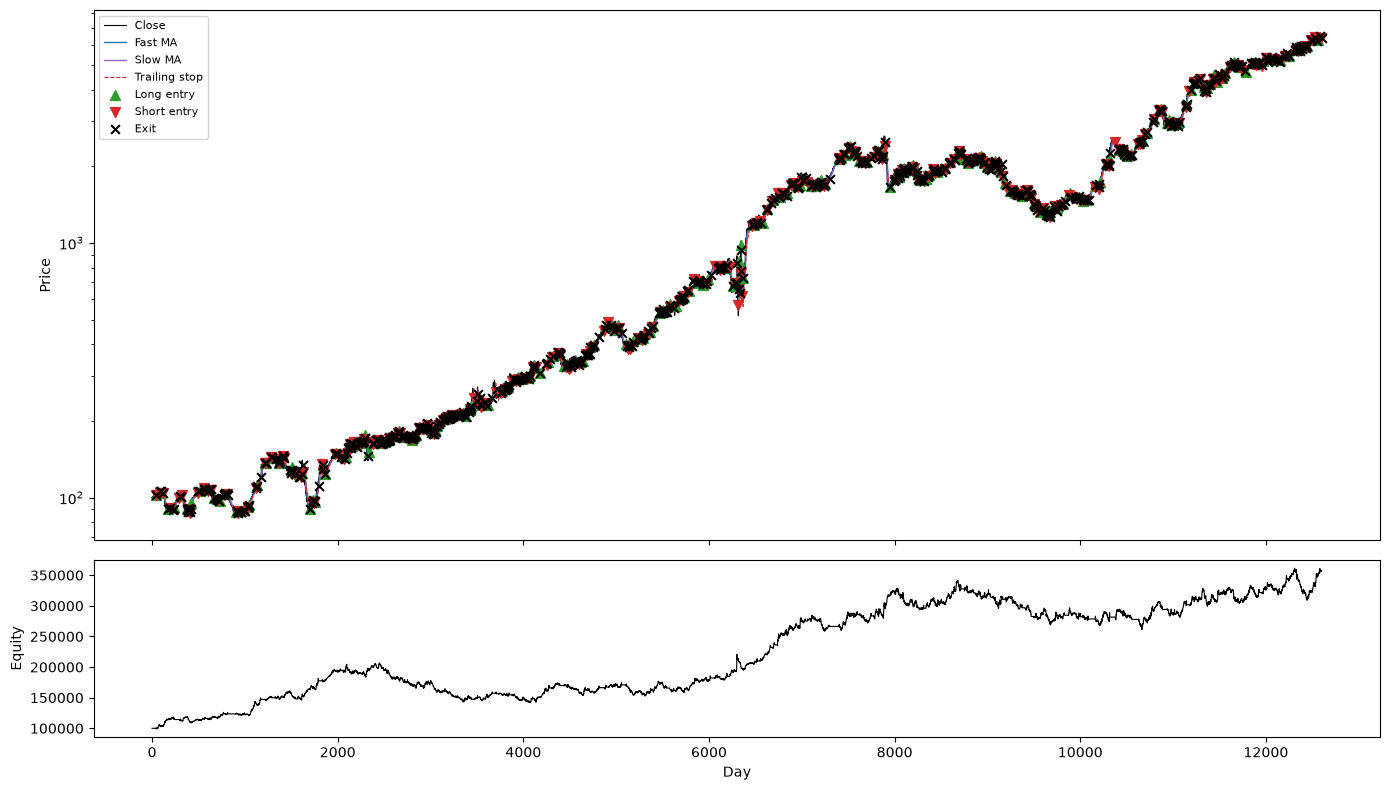

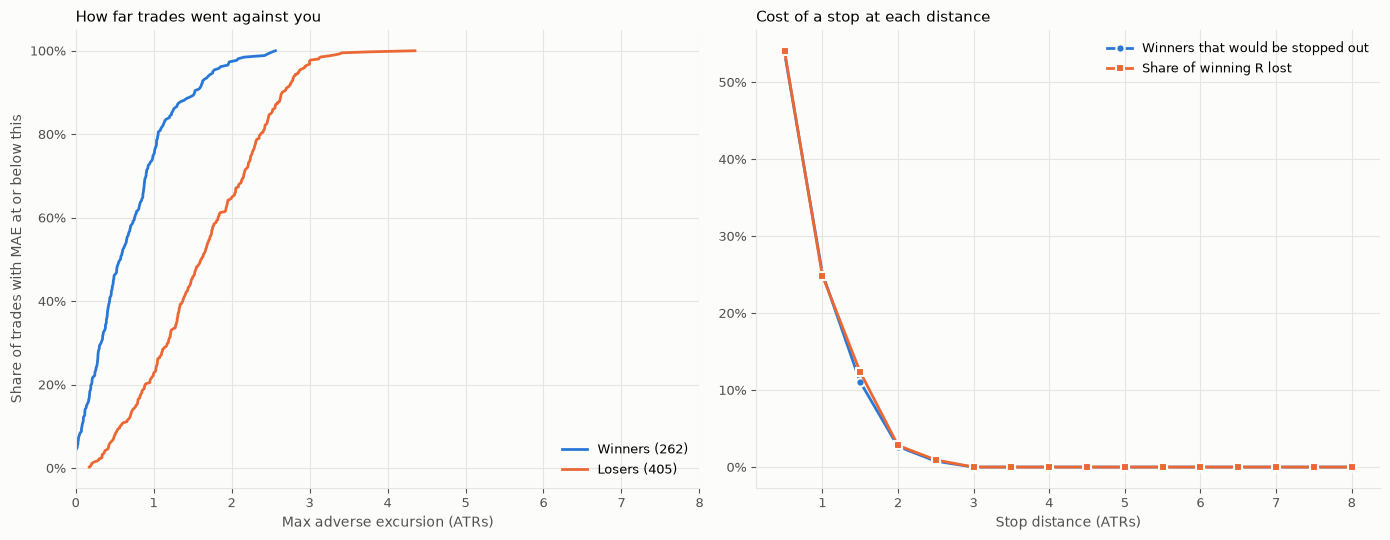

In [10]:
SEED = random.randint(0,1000000)
df  = gen.generate(T=252*50, S0=100.0, seed=SEED)
res = backtest_ma_atr(df, fast=10, slow=20, atr_period=14, trail_mult=3.0,cost_bps=0,sizing={'method': 'fixed_risk', 'risk_pct': 0.02})
# res = backtest_ma_atr(df, fast=10, slow=20, atr_period=14, trail_mult=3, cost_bps=0)
plot_backtest(res)
plot_mae(res['trades'], unit='atr', levels=None)


In [11]:
import os
from concurrent.futures import ProcessPoolExecutor, as_completed
def _run_seed_chunk(gen, seeds, configs, T, S0, common):
    """Worker: generate each path from its seed and run every config on it."""
    rows = []
    for seed in seeds:
        df = gen.generate(T=T, S0=S0, seed=seed)
        lr = df['log_return']
        buy_hold_sharpe = lr.mean() / lr.std() * np.sqrt(252)
        for name, params in configs.items():
            p = {**common, **params}
            res = backtest_ma_atr(df, **p)
            s = pd.concat([trade_stats(res['trades']),
                           equity_stats(res['daily'], p.get('initial_equity', 100_000.0))])
            s['buy_hold_sharpe'] = buy_hold_sharpe
            s['seed'] = seed
            s['config'] = name
            rows.append(s.to_dict())
    return rows
 
 
def compare_parallel(gen, seeds, configs, T=252 * 20, S0=100.0, n_jobs=None,
                     chunk_size=10, return_per_path=False, **common):
    """
    Same output as compare(), but split across CPU cores.
 
    Paths are generated inside the workers from their seeds, so you don't need
    generate_paths() first and the paths are never held in memory all at once.
    Results are identical to compare() on the same seeds.
 
    gen         : a SyntheticMarketGenerator (its class must be defined in a module, e.g. bf)
    seeds       : e.g. range(1000, 6000)
    n_jobs      : number of worker processes (default: all cores but one)
    chunk_size  : seeds per task; larger means less overhead but a jumpier progress bar
    return_per_path : also return every path's stats for every config
    common      : parameters shared by every config (e.g. cost_bps=5)
    """
    seeds = list(seeds)
    n_jobs = n_jobs or max(1, (os.cpu_count() or 2) - 1)
    chunks = [seeds[i:i + chunk_size] for i in range(0, len(seeds), chunk_size)]
 
    rows = []
    with ProcessPoolExecutor(max_workers=n_jobs) as pool, \
            tqdm(total=len(seeds) * len(configs), desc=f'Backtesting ({n_jobs} workers)') as bar:
        futures = {pool.submit(_run_seed_chunk, gen, chunk, configs, T, S0, common): len(chunk)
                   for chunk in chunks}
        for f in as_completed(futures):
            rows.extend(f.result())
            bar.update(futures[f] * len(configs))
 
    per_path = pd.DataFrame(rows)
    table = pd.DataFrame({
        name: summarise(per_path[per_path['config'] == name].set_index('seed').sort_index())
        for name in configs
    }).T
    return (table, per_path) if return_per_path else table

In [12]:
STOP_PCT   = 0.05   # percent stop distance
ATR_MULT   = 7      # ATR stop multiple
ATR_PERIOD = 14

paths = generate_paths(gen, range(1000), T=252*20, S0=100)

# Typical ATR as a % of price, so the "5% stop | vol target" rows take the same
# average risk per trade as their label
typical_atr_pct = np.median([
    (add_atr(df.copy(), ATR_PERIOD)[f'atr_{ATR_PERIOD}'] / df['close']).median()
    for df in list(paths.values())[:50]
])

risks = [0.005, 0.01, 0.02, 0.025, 0.05, 0.10, 0.25]
configs = {'notional 1x': {'sizing': {'method': 'notional', 'fraction': 1.0}}}

for r in risks:
    label = f'{r:.1%}'
    # ATR stop, sized by stop distance (= volatility-adjusted)
    configs[f'{ATR_MULT:g} ATR stop | risk {label}'] = {'stop_type': 'atr', 'trail_mult': ATR_MULT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'fixed_risk', 'risk_pct': r}}
    # Percent stop, sized by stop distance (= constant notional of r / STOP_PCT)
    configs[f'{STOP_PCT:.0%} stop | risk {label}'] = {'stop_type': 'percent', 'trail_pct': STOP_PCT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'fixed_risk', 'risk_pct': r}}
    # Percent stop, sized by ATR (volatility-adjusted size, fixed stop)
    configs[f'{STOP_PCT:.0%} stop | vol target {label}'] = {'stop_type': 'percent', 'trail_pct': STOP_PCT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'vol_target', 'atr_pct': r * typical_atr_pct / STOP_PCT}}
    # No stop, sized exactly like the ATR-stop rows, exit on opposite cross only
    configs[f'No stop | vol target {label}'] = {'stop_type': 'none', 'trail_mult': ATR_MULT, 'atr_period': ATR_PERIOD,'sizing': {'method': 'vol_target', 'atr_pct': r / ATR_MULT}}

table = compare(paths, configs, cost_bps=5)

Backtesting: 100%|██████████| 29000/29000 [08:38<00:00, 55.98it/s, No stop | vol target 25.0%]


In [13]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# Plots for the table returned by compare().
# Config names must end in a risk level such as "ATR stop | risk 1.0%".
# Everything before the number is treated as the family; names without a number
# (e.g. "notional 1x") are drawn as a grey reference.

FAMILY_COLOURS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']  # fixed order
FAMILY_MARKERS = ['o', 's', '^', 'D', 'v', 'P']
REF_COLOUR = '#8c8b86'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e6e5e1', '#fcfcfb'


def _parse(table):
    """Split each config name into family and risk level."""
    rows = []
    for name in table.index:
        m = re.match(r'^(.*?)\s*([\d.]+)%\s*$', name)
        if m:
            rows.append({'name': name, 'family': m.group(1).strip(), 'risk': float(m.group(2)) / 100})
        else:
            rows.append({'name': name, 'family': None, 'risk': np.nan})
    meta = pd.DataFrame(rows).set_index('name')
    out = table.join(meta)
    families = list(dict.fromkeys(meta['family'].dropna()))  # order of first appearance
    return out, families


def _style(ax):
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_2, labelsize=9)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)
    ax.title.set_color(INK)


def _legend_handles(families, has_ref):
    handles = [Line2D([0], [0], color=FAMILY_COLOURS[i], marker=FAMILY_MARKERS[i], lw=2, ms=7,
                      mec=SURFACE, mew=1.5, label=f)
               for i, f in enumerate(families)]
    if has_ref:
        handles.append(Line2D([0], [0], color=REF_COLOUR, ls='--', lw=1.5, label='Notional 1x (reference)'))
    return handles


def plot_frontier(table):
    """Median CAGR against tail drawdown, one line per family running from low to high risk."""
    df, families = _parse(table)
    ref = df[df['family'].isna()]

    fig, ax = plt.subplots(figsize=(10, 6.5), facecolor=SURFACE)
    _style(ax)
    ax.axhline(0, color=INK_2, lw=0.8)

    for i, fam in enumerate(families):
        sub = df[df['family'] == fam].sort_values('risk')
        x, y = sub['max_dd_p95'] * 100, sub['cagr_median'] * 100
        ax.plot(x, y, color=FAMILY_COLOURS[i], lw=2, marker=FAMILY_MARKERS[i], ms=7,
                mec=SURFACE, mew=1.5, zorder=3)
        # Label only the highest risk level (low-risk ends cluster near the origin)
        ax.annotate(f"{sub['risk'].iloc[-1] * 100:g}%", (x.iloc[-1], y.iloc[-1]),
                    textcoords='offset points', xytext=(6, 4), fontsize=8, color=INK_2)

    for name, row in ref.iterrows():
        ax.scatter(row['max_dd_p95'] * 100, row['cagr_median'] * 100, color=REF_COLOUR,
                   s=60, edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ax.annotate(name, (row['max_dd_p95'] * 100, row['cagr_median'] * 100),
                    textcoords='offset points', xytext=(6, 4), fontsize=8, color=INK_2)

    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}%'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}%'))
    ax.set_xlabel('Tail drawdown: 95th percentile of max drawdown across paths')
    ax.set_ylabel('Median CAGR')
    ax.set_title('Return vs tail drawdown (each line runs from lowest to highest risk %)',
                 loc='left', fontsize=12)
    ax.legend(handles=_legend_handles(families, False), loc='upper left', frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_by_risk(table, dd_threshold=30):
    """Small multiples of the key metrics against risk %, one line per family."""
    df, families = _parse(table)
    ref = df[df['family'].isna()]
    risks = np.sort(df['risk'].dropna().unique())

    metrics = [
        ('cagr_median', 'Median CAGR', True),
        ('sharpe_median', 'Median Sharpe', False),
        ('max_dd_p95', 'Tail drawdown (95th pct of max DD)', True),
        (f'p_dd_over_{dd_threshold}', f'Share of paths with max DD > {dd_threshold}%', True),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True, facecolor=SURFACE)
    for ax, (col, title, is_pct) in zip(axes.flat, metrics):
        _style(ax)
        for i, fam in enumerate(families):
            sub = df[df['family'] == fam].sort_values('risk')
            ax.plot(sub['risk'] * 100, sub[col] * (100 if is_pct else 1), color=FAMILY_COLOURS[i],
                    lw=2, marker=FAMILY_MARKERS[i], ms=7, mec=SURFACE, mew=1.5, zorder=3)
        for _, row in ref.iterrows():
            ax.axhline(row[col] * (100 if is_pct else 1), color=REF_COLOUR, ls='--', lw=1.5, zorder=2)

        ax.set_xscale('log')
        ax.set_xticks(risks * 100)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}%'))
        ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
        if is_pct:
            ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}%'))
        ax.set_title(title, loc='left', fontsize=11)

    for ax in axes[1]:
        ax.set_xlabel('Risk per trade (log scale)')
    fig.legend(handles=_legend_handles(families, len(ref) > 0), loc='upper center',
               ncol=len(families) + 1, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.0))
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

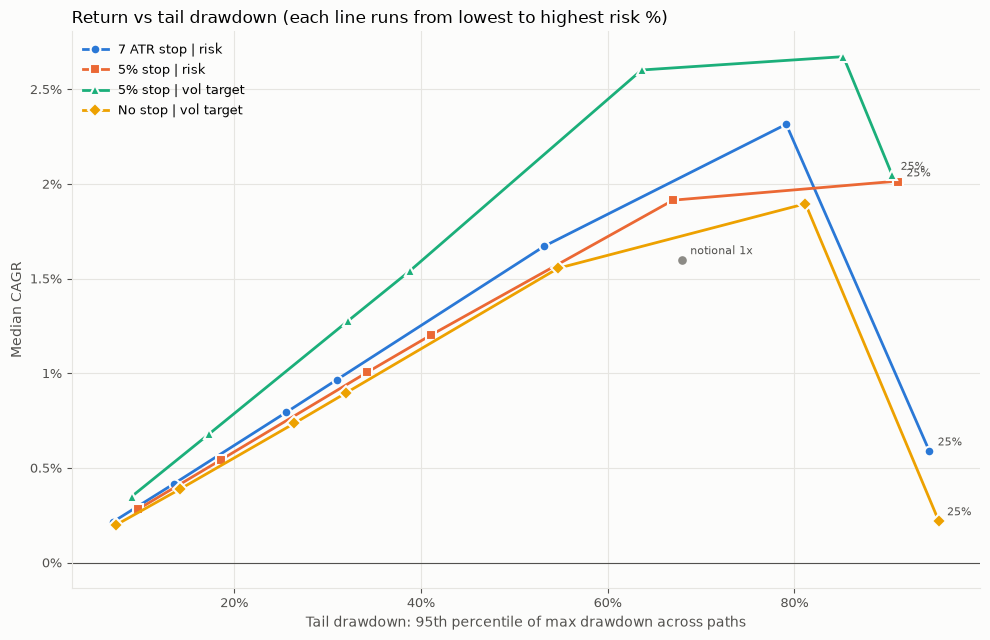

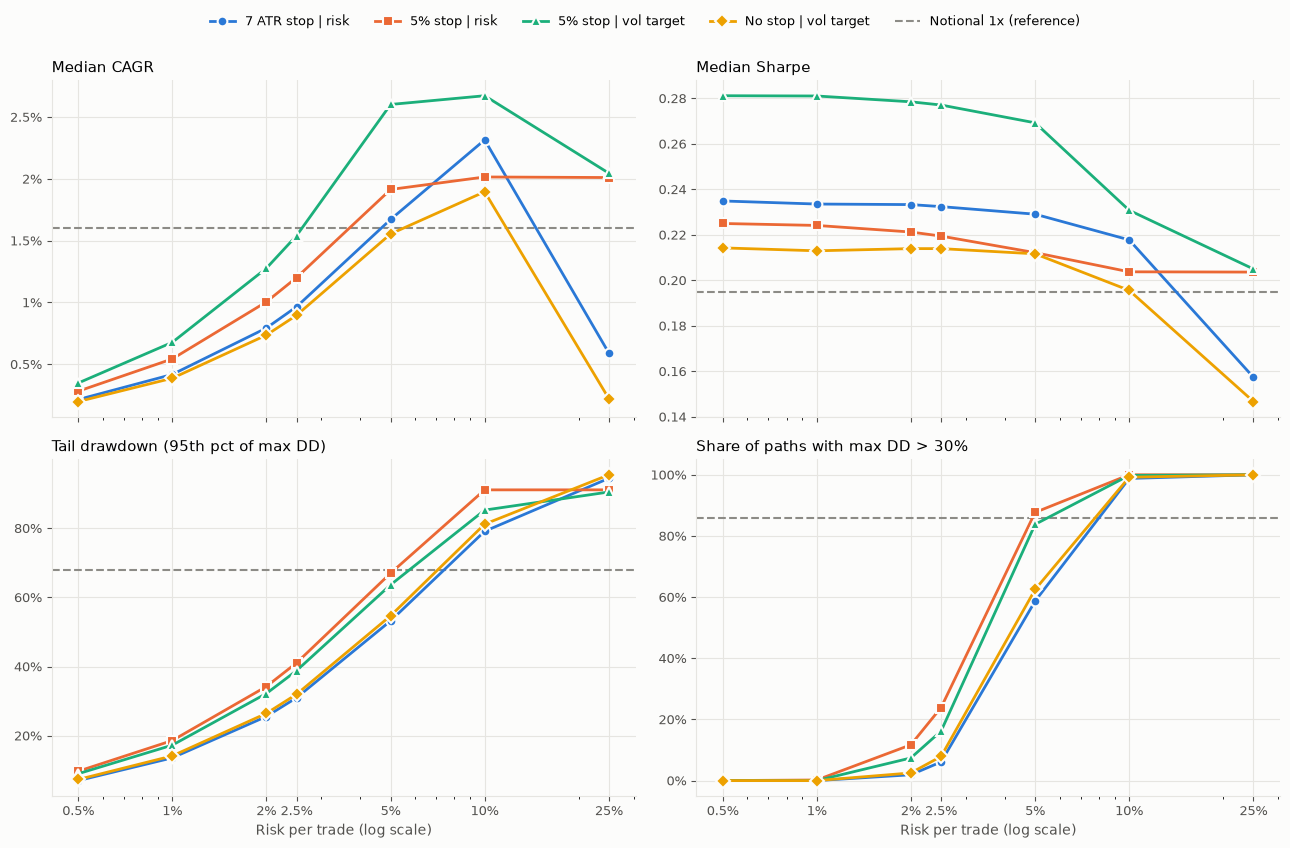

In [15]:
plot_frontier(table)
plot_by_risk(table)

Generating paths: 100%|██████████| 10000/10000 [05:47<00:00, 28.74it/s]


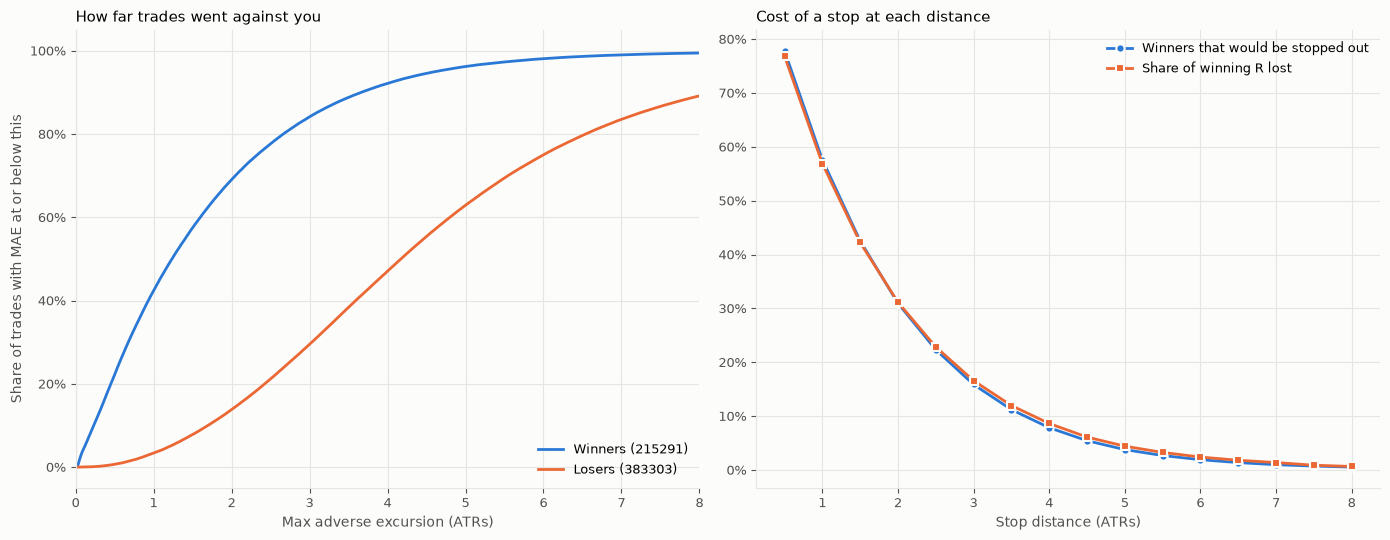

In [594]:
paths = generate_paths(gen, range(10000), T=252*20, S0=100)
_, pooled_ns = run_many(paths, stop_type='none', cost_bps=5)
mae_profile(pooled_ns, unit='atr')   # or unit='pct'
plot_mae(pooled_ns, unit='atr')

In [599]:
[i+1 for i in range(12)]

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Sweeping trail_mult: 100%|██████████| 10/10 [23:13<00:00, 139.35s/it]

Note: the best calibration sharpe is at the edge of the range (8). Extend the range in that direction before trusting the chosen width.


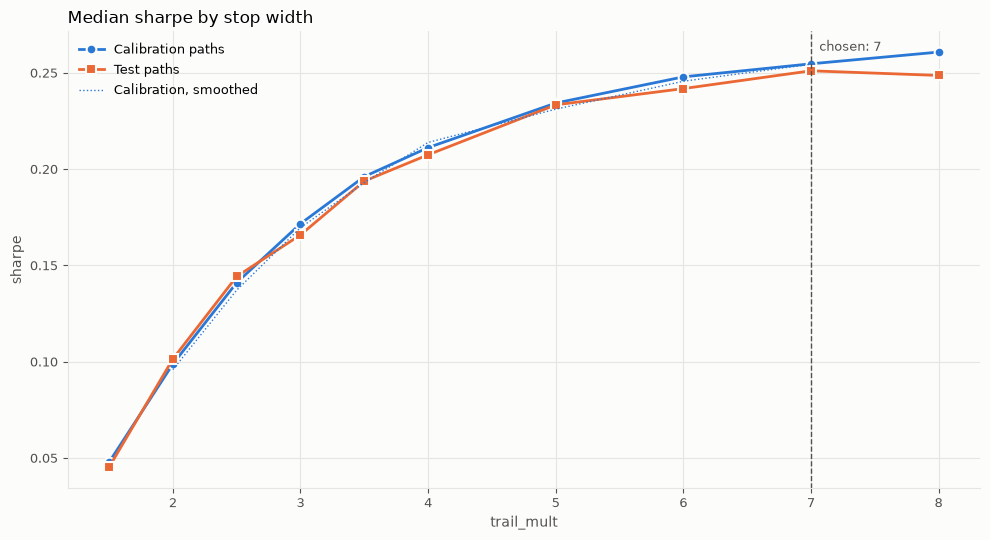

Sweeping trail_pct: 100%|██████████| 8/8 [19:16<00:00, 144.57s/it]


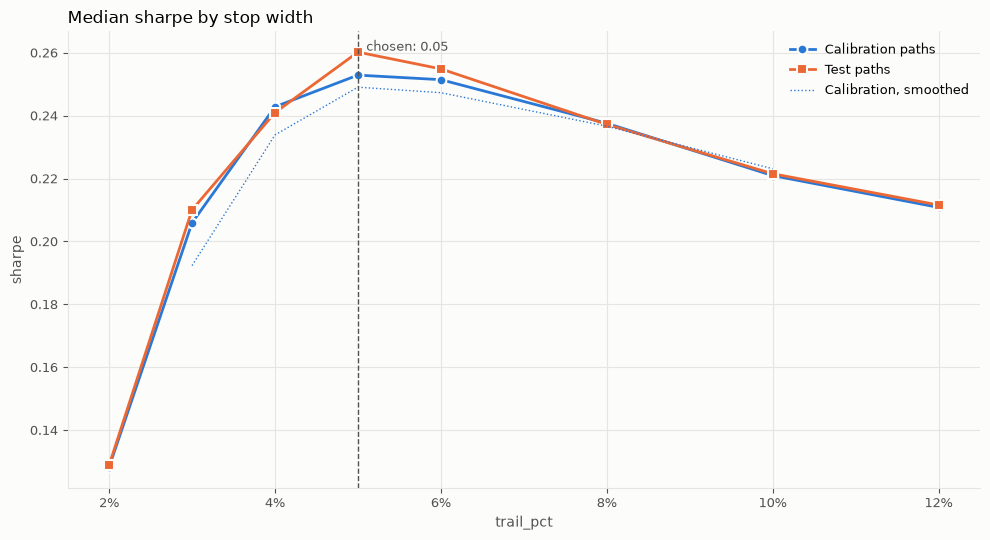

In [ ]:
sw_atr = stop_sweep(paths, 'trail_mult', [1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8],
                    stop_type='atr', cost_bps=5)
plot_stop_sweep(sw_atr)

sw_pct = stop_sweep(paths, 'trail_pct', [0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12],
                    stop_type='percent', cost_bps=5)
plot_stop_sweep(sw_pct)

In [597]:
display(sw_pct)
display(sw_atr)

,calib_sharpe,calib_cagr,calib_max_dd_p95,calib_win_rate,calib_profit_factor,calib_trades_per_year,test_sharpe,test_cagr,test_max_dd_p95,test_win_rate,test_profit_factor,test_trades_per_year,calib_sharpe_smoothed,chosen
trail_pct,,,,,,,,,,,,,,
0.02,0.128238,0.001208,0.077872,0.377779,1.224028,3.0,0.128847,0.001222,0.077388,0.377934,1.225812,3.0,NaN,False
0.03,0.205901,0.001902,0.068954,0.386944,1.368199,3.0,0.210028,0.001954,0.070864,0.386807,1.361310,3.0,0.192314,False
0.04,0.242803,0.002201,0.065123,0.387184,1.437573,3.0,0.240949,0.002181,0.066274,0.387699,1.436735,3.0,0.233860,False
0.05,0.252876,0.002234,0.062050,0.383120,1.470383,3.0,0.260197,0.002260,0.063812,0.383309,1.465702,3.0,0.249035,True
0.06,0.251427,0.002104,0.060394,0.378093,1.472976,3.0,0.254855,0.002122,0.061065,0.377587,1.465722,3.0,0.247287,False
0.08,0.237559,0.001781,0.056639,0.369484,1.445765,3.0,0.237201,0.001776,0.056192,0.368137,1.443114,3.0,0.236641,False
0.10,0.220938,0.001470,0.051624,0.365259,1.421997,3.0,0.221525,0.001484,0.050929,0.363076,1.419590,3.0,0.223107,False
0.12,0.210826,0.001229,0.046282,0.362841,1.401295,3.0,0.211575,0.001247,0.045722,0.360265,1.401469,3.0,NaN,False


,calib_sharpe,calib_cagr,calib_max_dd_p95,calib_win_rate,calib_profit_factor,calib_trades_per_year,test_sharpe,test_cagr,test_max_dd_p95,test_win_rate,test_profit_factor,test_trades_per_year,calib_sharpe_smoothed,chosen
trail_mult,,,,,,,,,,,,,,
1.5,0.047847,0.000408,0.081489,0.369166,1.083626,3.0,0.045274,0.000393,0.083451,0.369582,1.084198,3.0,NaN,False
2.0,0.098829,0.000864,0.074433,0.380231,1.175944,3.0,0.101443,0.000892,0.075565,0.380788,1.177725,3.0,0.095916,False
2.5,0.141071,0.001233,0.070061,0.386500,1.245605,3.0,0.144276,0.001268,0.070948,0.387295,1.251648,3.0,0.137190,False
3.0,0.171671,0.001482,0.066398,0.389545,1.308560,3.0,0.165872,0.001419,0.067384,0.390720,1.303581,3.0,0.169620,False
3.5,0.196118,0.001663,0.063453,0.390657,1.357121,3.0,0.193782,0.001643,0.065215,0.391167,1.354176,3.0,0.192991,False
4.0,0.211186,0.001801,0.061568,0.390213,1.394465,3.0,0.207459,0.001755,0.062593,0.390059,1.390428,3.0,0.213870,False
5.0,0.234307,0.001959,0.060656,0.385317,1.454742,3.0,0.233371,0.001951,0.062135,0.384948,1.449694,3.0,0.231135,False
6.0,0.247912,0.002034,0.058538,0.378558,1.500809,3.0,0.241823,0.001962,0.058726,0.377544,1.494199,3.0,0.245637,False
7.0,0.254693,0.002027,0.055724,0.371861,1.530795,3.0,0.251064,0.001998,0.055983,0.370964,1.526155,3.0,0.254463,True


In [600]:
sw_atr = stop_sweep(paths, 'trail_mult', [i+1 for i in range(12)],
                    stop_type='atr', cost_bps=5)
plot_stop_sweep(sw_atr)

Sweeping trail_mult:  67%|██████▋   | 8/12 [23:31<11:45, 176.39s/it]


KeyboardInterrupt: 